# 10 — Part 2 data audit: diabetes, blood pressure and kidney disease (NHANES 2007–2018)
**Plan:** [`docs/part2_plan.md`](../docs/part2_plan.md), committed before any outcome was examined.

This notebook checks the Part 2 data before modelling. **Outcomes (HbA1c, kidney markers) are examined for the training years
(2007–2014) only.** For the test years (2015–2018), only the inputs are checked, so the test set stays untouched until the final evaluation.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score

from src.part2_data import load, INPUTS, CKD_INPUTS

sns.set_theme(style="whitegrid")
df = load()
train = df[df.split == "train"]
print(df.groupby(["split", "cycle"]).size().rename("adults 20+, examined, not pregnant").to_frame())

                 adults 20+, examined, not pregnant
split cycle                                        
test  2015-2016                                5404
      2017-2018                                5210
train 2007-2008                                5650
      2009-2010                                5991
      2011-2012                                5262
      2013-2014                                5523


## 1. Who is in each target's population?

In [2]:
pop = pd.DataFrame({
    "adults": df.groupby("split").size(),
    "diabetes target (not diagnosed, HbA1c measured)": df.groupby("split").UndxDiabetes.count(),
    "kidney target (not told of kidney disease, markers measured)": df.groupby("split").UndxCKD.count(),
})
pop

,adults,"diabetes target (not diagnosed, HbA1c measured)","kidney target (not told of kidney disease, markers measured)"
split,,,
test,10614,8523,9525
train,22426,18630,20326


## 2. Missing inputs, by survey cycle (inputs only, all years)

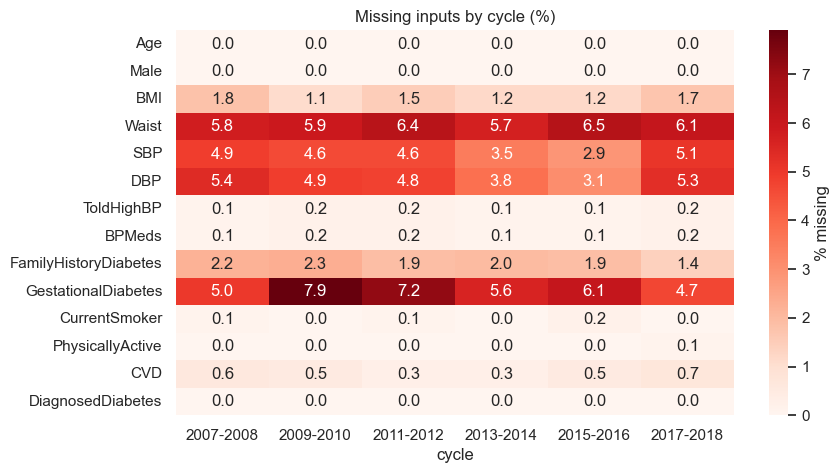

In [3]:
miss = df.groupby("cycle")[CKD_INPUTS].apply(lambda g: g.isna().mean() * 100).round(1).T
plt.figure(figsize=(9, 5))
sns.heatmap(miss, annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "% missing"})
plt.title("Missing inputs by cycle (%)")
plt.show()

## 3. Did the population change between training and test years? (inputs only)
The model will be tested on later years. If the people in those years differ, that alone can change performance.

In [4]:
num = ["Age", "BMI", "Waist", "SBP", "DBP"]
binary = ["Male", "ToldHighBP", "BPMeds", "FamilyHistoryDiabetes", "CurrentSmoker", "PhysicallyActive", "CVD",
          "DiagnosedDiabetes", "Hypertension", "CDCHighRisk", "KDIGOPriority"]
drift = pd.concat([
    df.groupby("split")[num].median().T.assign(stat="median"),
    (df.groupby("split")[binary].mean() * 100).T.assign(stat="% yes"),
])[["stat", "train", "test"]]
drift["difference"] = drift["test"] - drift["train"]
drift.round(1)

split,stat,train,test,difference
Age,median,49.0,51.0,2.0
BMI,median,27.9,28.5,0.6
Waist,median,97.5,99.1,1.6
SBP,median,120.7,123.3,2.7
DBP,median,70.7,71.3,0.7
Male,% yes,49.1,48.7,-0.5
ToldHighBP,% yes,36.4,37.7,1.3
BPMeds,% yes,28.0,29.0,1.0
FamilyHistoryDiabetes,% yes,40.4,46.4,6.0
CurrentSmoker,% yes,21.3,18.6,-2.7


## 4. How common are the conditions? (training years only)
Unweighted rates describe the people sampled. Weighted rates use NHANES examination weights to estimate the US adult population.

In [5]:
def rates(g, col):
    v = g[col].notna()
    return pd.Series({"n": int(v.sum()), "cases": int(g.loc[v, col].sum()),
                      "unweighted %": g.loc[v, col].mean() * 100,
                      "weighted %": np.average(g.loc[v, col], weights=g.loc[v, "weight"]) * 100})

prev = pd.DataFrame({name: rates(train, col) for name, col in [
    ("Undiagnosed diabetes (HbA1c ≥ 6.5 %)", "UndxDiabetes"),
    ("Undiagnosed prediabetes or diabetes (HbA1c ≥ 5.7 %)", "UndxDysglycemia"),
    ("Undiagnosed CKD markers (eGFR < 60 or ACR ≥ 30)", "UndxCKD"),
    ("Hypertension (known or measured)", "Hypertension"),
]}).T
prev.round(1)

,n,cases,unweighted %,weighted %
Undiagnosed diabetes (HbA1c ≥ 6.5 %),18630.0,697.0,3.7,2.5
Undiagnosed prediabetes or diabetes (HbA1c ≥ 5.7 %),18630.0,6043.0,32.4,26.3
Undiagnosed CKD markers (eGFR < 60 or ACR ≥ 30),20326.0,3440.0,16.9,13.0
Hypertension (known or measured),22426.0,9555.0,42.6,37.6


In [6]:
by_cycle = train.groupby("cycle")[["UndxDiabetes", "UndxCKD"]].mean().mul(100).round(1)
by_cycle.columns = ["undiagnosed diabetes %", "undiagnosed CKD markers %"]
by_cycle

,undiagnosed diabetes %,undiagnosed CKD markers %
cycle,,
2007-2008,4.1,18.7
2009-2010,3.8,15.5
2011-2012,3.9,17.0
2013-2014,3.2,16.5


In [7]:
ckd = train[train.UndxCKD == 1]
print(f"Among training-year adults with undiagnosed CKD markers (n={len(ckd)}):")
print(f"  low eGFR (<60) only:       {((ckd.eGFR < 60) & ~(ckd.ACR >= 30)).mean():.0%}")
print(f"  high albumin (ACR≥30) only: {(~(ckd.eGFR < 60) & (ckd.ACR >= 30)).mean():.0%}")
print(f"  both:                      {((ckd.eGFR < 60) & (ckd.ACR >= 30)).mean():.0%}")

Among training-year adults with undiagnosed CKD markers (n=3440):
  low eGFR (<60) only:       28%
  high albumin (ACR≥30) only: 60%
  both:                      12%


## 5. How do the three conditions overlap? (training years only)
These are people in both target populations: never diagnosed with diabetes or with kidney disease, and with all labs measured.

In [8]:
both = train[train.UndxDiabetes.notna() & train.UndxCKD.notna()]
print(f"Adults in both target populations: {len(both)}\n")
cond = pd.DataFrame({
    "CKD markers %": [both.loc[both.UndxDiabetes == v, "UndxCKD"].mean() * 100 for v in [0, 1]],
    "hypertension %": [both.loc[both.UndxDiabetes == v, "Hypertension"].mean() * 100 for v in [0, 1]],
    "n": [int((both.UndxDiabetes == v).sum()) for v in [0, 1]],
}, index=["no undiagnosed diabetes", "undiagnosed diabetes"])
print("Conditional on undiagnosed diabetes:"); display(cond.round(1))
cond2 = pd.DataFrame({
    "undiagnosed diabetes %": [both.loc[both.Hypertension == v, "UndxDiabetes"].mean() * 100 for v in [0, 1]],
    "CKD markers %": [both.loc[both.Hypertension == v, "UndxCKD"].mean() * 100 for v in [0, 1]],
    "n": [int((both.Hypertension == v).sum()) for v in [0, 1]],
}, index=["no hypertension", "hypertension"])
print("Conditional on hypertension:"); display(cond2.round(1))

Adults in both target populations: 17835

Conditional on undiagnosed diabetes:


,CKD markers %,hypertension %,n
no undiagnosed diabetes,12.5,35.8,17180
undiagnosed diabetes,30.4,63.2,655


Conditional on hypertension:


,undiagnosed diabetes %,CKD markers %,n
no hypertension,2.1,7.2,11264
hypertension,6.3,23.4,6571


In [9]:
combo = both.assign(D=both.UndxDiabetes.astype(int), K=both.UndxCKD.astype(int), H=both.Hypertension.astype(int))
pattern = combo.groupby(["H", "D", "K"]).size().rename("adults").reset_index()
pattern["share %"] = (pattern.adults / pattern.adults.sum() * 100).round(1)
pattern["pattern"] = pattern.apply(lambda r: " + ".join([n for n, v in [("hypertension", r.H), ("diabetes", r.D), ("CKD markers", r.K)] if v]) or "none", axis=1)
pattern[["pattern", "adults", "share %"]].sort_values("adults", ascending=False)

,pattern,adults,share %
0,none,10263,57.5
4,hypertension,4768,26.7
5,hypertension + CKD markers,1389,7.8
1,CKD markers,760,4.3
6,hypertension + diabetes,266,1.5
2,diabetes,190,1.1
7,hypertension + diabetes + CKD markers,148,0.8
3,diabetes + CKD markers,51,0.3


## 6. How do the official baselines behave? (training years only)

In [10]:
def baseline(g, target, rule):
    v = g[target].notna()
    y, r = g.loc[v, target], g.loc[v, rule]
    return pd.Series({"refers %": r.mean() * 100, "sensitivity %": r[y == 1].mean() * 100,
                      "PPV %": y[r == 1].mean() * 100, "cases found per 100 referrals": y[r == 1].mean() * 100})

pd.DataFrame({
    "Diabetes: CDC/ADA score ≥ 5": baseline(train, "UndxDiabetes", "CDCHighRisk"),
    "Diabetes: age 35–70 & BMI ≥ 25": baseline(train, "UndxDiabetes", "USPSTFRule"),
    "Prediabetes/diabetes: CDC/ADA score ≥ 5": baseline(train, "UndxDysglycemia", "CDCHighRisk"),
    "CKD: KDIGO priority groups": baseline(train, "UndxCKD", "KDIGOPriority"),
}).T.drop(columns="cases found per 100 referrals").round(1)

,refers %,sensitivity %,PPV %
Diabetes: CDC/ADA score ≥ 5,39.7,82.2,7.8
Diabetes: age 35–70 & BMI ≥ 25,42.3,64.4,5.7
Prediabetes/diabetes: CDC/ADA score ≥ 5,39.7,62.9,51.5
CKD: KDIGO priority groups,46.1,77.8,28.6


## 7. Which single inputs carry signal? (training years only, ROC-AUC per input)

In [11]:
def single_auc(g, target, cols):
    out = {}
    for c in cols:
        v = g[target].notna() & g[c].notna()
        if g.loc[v, c].nunique() > 1:
            out[c] = roc_auc_score(g.loc[v, target], g.loc[v, c])
    return pd.Series(out)

aucs = pd.DataFrame({"undiagnosed diabetes": single_auc(train, "UndxDiabetes", INPUTS + ["CDCScore"]),
                     "undiagnosed CKD markers": single_auc(train, "UndxCKD", CKD_INPUTS + ["CDCScore"])}).round(3)
aucs.sort_values("undiagnosed diabetes", ascending=False)

,undiagnosed diabetes,undiagnosed CKD markers
CDCScore,0.774,0.717
Waist,0.732,0.590
BMI,0.703,0.547
Age,0.685,0.748
SBP,0.659,0.676
ToldHighBP,0.611,0.661
BPMeds,0.603,0.661
FamilyHistoryDiabetes,0.587,0.524
CVD,0.548,0.588
DBP,0.543,0.469


## 8. Findings and decisions for modelling
| # | Finding (training years unless stated) | Decision |
|---|---|---|
| 1 | Large samples: **18,630** adults in the diabetes target (697 cases, 3.7 %) and **20,326** in the kidney target (3,440 cases, 16.9 %). Weighted US estimates: 2.5 % and 13.0 %. | Undiagnosed diabetes is rare, so **PR-AUC** matters alongside ROC-AUC. No class weighting, to keep probabilities honest (as in Part 1). |
| 2 | **The three conditions cluster.** Undiagnosed diabetes: 30 % have kidney markers vs 12.5 % without it. Hypertension: 6.3 % vs 2.1 % undiagnosed diabetes, and 23 % vs 7 % kidney markers. | The interconnection analyses (plan §7.3) are well motivated. Hypertension stays an input to both models. |
| 3 | **The baselines are strong.** The CDC/ADA score ≥ 5 refers 40 % and catches 82 % of undiagnosed diabetes. KDIGO groups refer 46 % and catch 78 % of kidney cases. The CDC score alone has ROC-AUC 0.77, higher than any single input. | Expect **modest** gains at best. The models must *combine* inputs to beat a score that already combines several. |
| 4 | **Waist** (AUC 0.73) beats BMI (0.70) for diabetes. **Age** dominates for kidney markers (0.75). Lower diastolic BP goes with kidney markers (AUC 0.47), which suggests non-linear effects in older adults. | Keep waist and BMI. Compare gradient boosting with logistic regression (plan §6), since some relations aren't straight lines. |
| 5 | **60 % of kidney cases are raised albumin only** (single urine test). KDIGO requires abnormalities lasting 3 months, so a single albumin result overstates CKD. | **Added before modelling:** a sensitivity analysis using an eGFR < 60-only kidney target (logged in the plan). |
| 6 | **Input drift (all years, inputs only):** test years are slightly older (median 51 vs 49), with more family history of diabetes (46 % vs 40 %) and more diagnosed diabetes (15.5 % vs 12.6 %). The CDC high-risk share rises from 46 % to 50 %. | The temporal test will show whether this shift affects performance. Report calibration in the test years. |
| 7 | Missing inputs are low (≤ 6 %), except gestational diabetes for women without a reproductive-health record. | Median imputation inside pipelines, as in Part 1. |